# 05 — Final comparison of all models

**Project:** Irony detection in tweets — TweetEval `irony` (SemEval-2018 Task 3)
**This notebook:** evaluate every model of the project on the **test set**, put them in one comparison table and justify the choice of the final model.
**Tools:** pandas · scikit-learn · matplotlib

**Where the models come from**
- Naive Bayes, Logistic Regression → notebook 02 (task B)
- SVM, Random Forest, KNN → notebook 03 (task C)
- Twitter-RoBERTa (transformer) → notebook 04 (task D)

The classical models are **rebuilt from the settings each task chose by cross-validation** (the `params` column of `results/metrics_B.csv` and `metrics_C.csv`) with the shared `build_pipeline()`, then trained once on the training set. The transformer's test scores are read from `results/metrics_D.csv` (it needs a GPU and was evaluated in notebook 04).

## 1. Imports

In [1]:
import sys
sys.path.append("..")

import ast
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)

from src.config import PROCESSED_DIR, RESULTS, RANDOM_STATE, TEXT_COL, LABEL_NAMES
from src.model import build_pipeline

## 2. Data

Same cleaned files as every other notebook (Task A's `text_clean`). The test set is used here for the first and only time for the classical models.

**Two versions of the test set.** Notebook 04 showed that every ironic test tweet still contains `#not`, `#irony` or `#sarcasm` (these hashtags were deleted from train and validation, not from test). So we evaluate every model on the **official test** and on the **test with these hashtags removed** — the second one is the fair comparison, because no model saw these hashtags during training.

In [2]:
train = pd.read_csv(PROCESSED_DIR / "train.csv", keep_default_na=False)
test = pd.read_csv(PROCESSED_DIR / "test.csv", keep_default_na=False)

X_train, y_train = train[TEXT_COL], train["label"]
y_test = test["label"].to_numpy()

HASHTAG_RE = re.compile(r"#(?:not|irony|sarcasm)\b", flags=re.IGNORECASE)

TEST_SETS = {
    "test": test[TEXT_COL],
    "test_no_hashtags": test[TEXT_COL].str.replace(HASHTAG_RE, "", regex=True).str.split().str.join(" "),
}

print("train:", X_train.shape, "| test:", y_test.shape)
print("test tweets containing #not/#irony/#sarcasm:", test[TEXT_COL].str.contains(HASHTAG_RE).sum())

train: (2859,) | test: (784,)
test tweets containing #not/#irony/#sarcasm: 431


## 3. The settings chosen by each task

Each task saved its tuned models to `results/metrics_<task>.csv`, with the validation scores and the hyperparameters chosen by 5-fold cross-validation on train.

In [3]:
SPLITS = {"validation", "test", "test_no_hashtags"}

def read_metrics(task):
    df = pd.read_csv(RESULTS / f"metrics_{task}.csv")
    return df[df["split"].isin(SPLITS)]          # ignore any malformed row

metrics = pd.concat([read_metrics(t) for t in ["B", "C", "D"]], ignore_index=True)
metrics[metrics["split"] == "validation"][["model", "f1_macro", "params"]].round(4)

,model,f1_macro,params
0,MultinomialNB,0.6314,clf=MultinomialNB(); clf__alpha=2.0
1,LogisticRegression,0.6469,clf__C=3; clf__class_weight=None
2,SVM tuned,0.6197,clf__C=0.5
3,Random Forest tuned,0.6126,clf__max_depth=None; clf__min_samples_leaf=1; ...
4,KNN tuned,0.6414,clf__metric=cosine; clf__n_neighbors=21; clf__...
5,Twitter-RoBERTa,0.7403,cardiffnlp/twitter-roberta-base; lr=2e-5; 4 ep...


## 4. Rebuilding the classical models

`params` is a text like `clf__C=3; clf__class_weight=None`. We turn it back into a dictionary (`{"clf__C": 3, "clf__class_weight": None}`) and give it to the shared pipeline with `set_params`, so each model is exactly the one its task selected.

In [4]:
ESTIMATORS = {"MultinomialNB": MultinomialNB, "ComplementNB": ComplementNB}

def parse_value(text):
    text = text.strip()
    if text.endswith("()") and text[:-2] in ESTIMATORS:      # e.g. "MultinomialNB()"
        return ESTIMATORS[text[:-2]]()
    try:
        return ast.literal_eval(text)                          # numbers, None, True, tuples...
    except (ValueError, SyntaxError):
        return text                                            # plain words: "cosine", "distance"

def parse_params(params):
    if not isinstance(params, str) or not params.strip():
        return {}
    pairs = [p.split("=", 1) for p in params.split(";")]
    return {key.strip(): parse_value(value) for key, value in pairs}

def base_classifier(model_name):
    name = model_name.lower()
    if "nb" in name or "bayes" in name:
        return MultinomialNB()
    if "logistic" in name:
        return LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    if "svm" in name or "svc" in name:
        return LinearSVC(max_iter=10000, random_state=RANDOM_STATE)
    if "forest" in name or name.startswith("rf"):
        return RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    if "knn" in name or "neighbor" in name:
        return KNeighborsClassifier()
    raise ValueError(f"Unknown model: {model_name}")

classical = metrics[(metrics["split"] == "validation") & (metrics["model"] != "Twitter-RoBERTa")]

models = {}
for _, row in classical.iterrows():
    pipe = build_pipeline(base_classifier(row["model"]))
    pipe.set_params(**parse_params(row["params"]))
    pipe.fit(X_train, y_train)
    models[row["model"]] = pipe
    print(f"{row['model']:<22} {parse_params(row['params'])}")

MultinomialNB          {'clf': MultinomialNB(), 'clf__alpha': 2.0}
LogisticRegression     {'clf__C': 3, 'clf__class_weight': None}


SVM tuned              {'clf__C': 0.5}


Random Forest tuned    {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
KNN tuned              {'clf__metric': 'cosine', 'clf__n_neighbors': 21, 'clf__weights': 'distance'}


## 5. Test evaluation of the classical models

In [5]:
def scores(model, split, y_true, y_pred):
    return {
        "model": model,
        "split": split,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }

test_rows, test_preds = [], {}
for name, pipe in models.items():
    for split, X in TEST_SETS.items():
        y_pred = pipe.predict(X)
        test_preds[(name, split)] = y_pred
        test_rows.append(scores(name, split, y_test, y_pred))

classical_test = pd.DataFrame(test_rows)
classical_test.round(4)

,model,split,accuracy,precision,recall,f1,f1_macro
0,MultinomialNB,test,0.6556,0.5547,0.6688,0.6064,0.6501
1,MultinomialNB,test_no_hashtags,0.6633,0.5575,0.7331,0.6333,0.6610
2,LogisticRegression,test,0.6441,0.5465,0.6045,0.5740,0.6342
3,LogisticRegression,test_no_hashtags,0.6645,0.5622,0.6977,0.6227,0.6604
4,SVM tuned,test,0.6531,0.5562,0.6206,0.5866,0.6439
5,SVM tuned,test_no_hashtags,0.6709,0.5692,0.7010,0.6282,0.6665
6,Random Forest tuned,test,0.6186,0.5180,0.5563,0.5364,0.6062
7,Random Forest tuned,test_no_hashtags,0.6365,0.5333,0.6688,0.5934,0.6324
8,KNN tuned,test,0.6135,0.5124,0.5305,0.5213,0.5986
9,KNN tuned,test_no_hashtags,0.6378,0.5368,0.6334,0.5811,0.6310


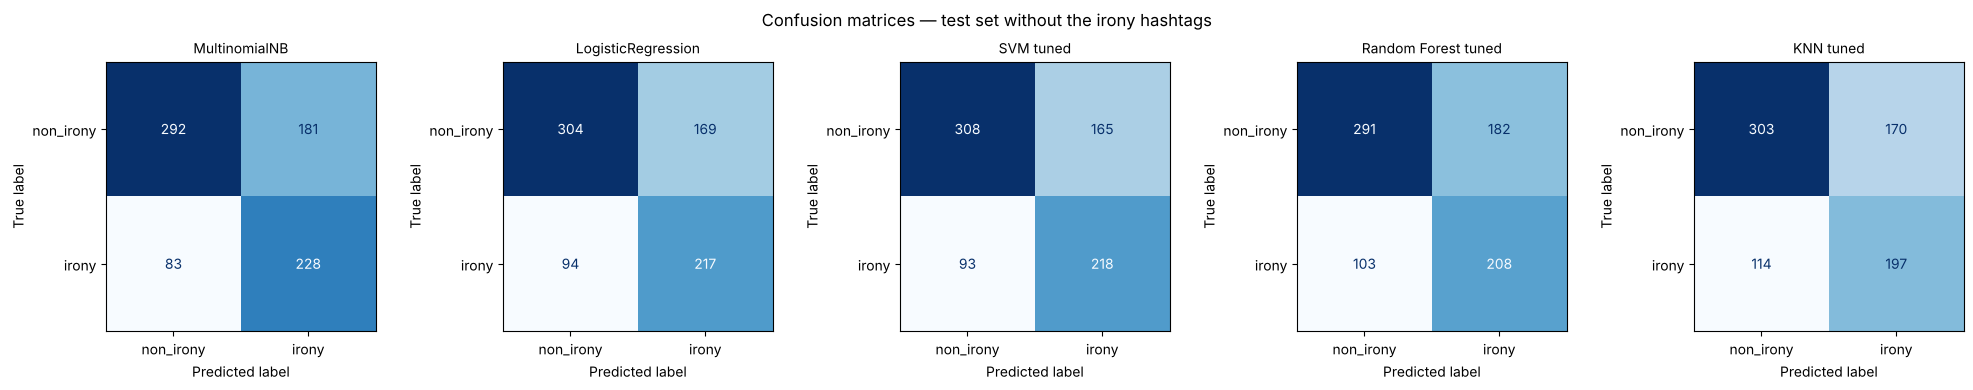

In [6]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.8))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_test, test_preds[(name, "test_no_hashtags")],
                                            display_labels=LABEL_NAMES, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.suptitle("Confusion matrices — test set without the irony hashtags")
plt.tight_layout()
plt.show()

## 6. Comparison table of all models

The transformer's rows come from `metrics_D.csv` (evaluated once in notebook 04, on the same two versions of the test set).

In [7]:
all_rows = pd.concat([
    metrics[metrics["split"].isin(["validation"])][["model", "split", "f1_macro"]],
    classical_test[["model", "split", "f1_macro"]],
    metrics[(metrics["model"] == "Twitter-RoBERTa") & metrics["split"].isin(["test", "test_no_hashtags"])][["model", "split", "f1_macro"]],
], ignore_index=True)

comparison = (all_rows.pivot_table(index="model", columns="split", values="f1_macro")
              [["validation", "test", "test_no_hashtags"]]
              .sort_values("test_no_hashtags", ascending=False)
              .round(3))
comparison

split,validation,test,test_no_hashtags
model,,,
Twitter-RoBERTa,0.740,0.773,0.741
SVM tuned,0.620,0.644,0.667
MultinomialNB,0.631,0.650,0.661
LogisticRegression,0.647,0.634,0.660
Random Forest tuned,0.613,0.606,0.632
KNN tuned,0.641,0.599,0.631


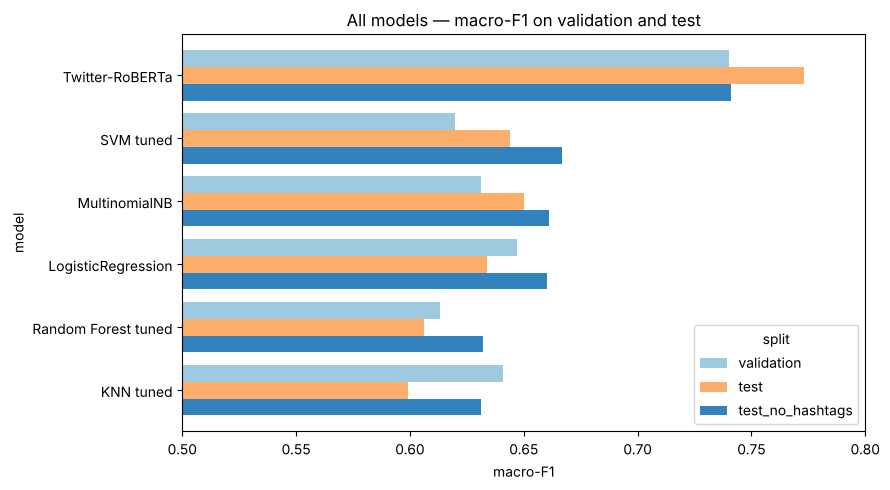

In [8]:
ax = comparison.plot(kind="barh", figsize=(9, 5), width=0.8, color=["#9ecae1", "#fdae6b", "#3182bd"])
ax.invert_yaxis()
ax.set_xlim(0.5, 0.8)
ax.set_xlabel("macro-F1")
ax.set_title("All models — macro-F1 on validation and test")
ax.legend(title="split", loc="lower right")
plt.tight_layout()
plt.show()

In [9]:
full_test = pd.concat([
    classical_test,
    metrics[(metrics["model"] == "Twitter-RoBERTa") & (metrics["split"] == "test_no_hashtags")],
], ignore_index=True)

(full_test[full_test["split"] == "test_no_hashtags"]
 .drop(columns=["split", "params"], errors="ignore")
 .sort_values("f1_macro", ascending=False)
 .set_index("model")
 .round(3))

,accuracy,precision,recall,f1,f1_macro
model,,,,,
Twitter-RoBERTa,0.746,0.654,0.765,0.705,0.741
SVM tuned,0.671,0.569,0.701,0.628,0.667
MultinomialNB,0.663,0.557,0.733,0.633,0.661
LogisticRegression,0.665,0.562,0.698,0.623,0.660
Random Forest tuned,0.636,0.533,0.669,0.593,0.632
KNN tuned,0.638,0.537,0.633,0.581,0.631


In [10]:
final_table = pd.concat([metrics, classical_test], ignore_index=True)
final_table.to_csv(RESULTS / "comparison_all_models.csv", index=False)
print("Saved: results/comparison_all_models.csv")

Saved: results/comparison_all_models.csv


## 7. Choice of the final model

**Final model: Twitter-RoBERTa** (notebook 04).

| | Best classical model (SVM) | Twitter-RoBERTa | Gain |
|---|---|---|---|
| Test macro-F1, hashtags removed (fair comparison) | 0.667 | **0.741** | **+0.074** |
| Test macro-F1, official | 0.650 (Naive Bayes) | **0.773** | +0.123 |
| Irony recall (hashtags removed) | 0.70 | **0.77** | |
| Irony precision (hashtags removed) | 0.57 | **0.65** | |

**Why this choice**
1. **It is the best model on every metric and every version of the test set**, by a large margin.
2. **The margin is far above the noise.** The five classical models are within 0.04 of each other and their order changes between validation and test (KNN is 2nd on validation, last on test; SVM is 4th on validation, 1st on test): their differences are mostly noise. The transformer's lead (+0.07) is much larger than those fluctuations, and notebook 04 showed that its own run-to-run noise is only ±0.003 (3 seeds).
3. **It is the only model that reads context.** TF-IDF models count words; irony lives in the contrast between words (*"I love waiting 2 hours at the doctor"*). The error analysis of notebook 04 shows the transformer wins precisely on those contrasts.
4. **Its validation estimate was honest:** 0.745 on validation (3 seeds) vs 0.741 on the fair test.

**Cost of this choice:** training needs a GPU (~2 min per run on an RTX 5060 Ti) and the model weighs ~500 MB, against a few seconds and a few MB for Logistic Regression. If a fast, light, explainable model were required, **Logistic Regression** would be the classical choice: almost as good as the best classical model, and its weights show which words signal irony (notebook 02).

## 8. Conclusion

**What the comparison shows**
- **Classical models plateau around 0.63–0.67 macro-F1.** Whatever the algorithm (probabilistic, linear, trees, neighbors), a bag of words only sees which words appear. On irony, that is not enough: the same word ("love", "great") is sincere in one tweet and ironic in the next.
- **Linear models do best among classical ones** (SVM, Naive Bayes, Logistic Regression), while Random Forest and KNN struggle with thousands of sparse TF-IDF features.
- **The leftover hashtags behave differently for the two families.** The classical models score *lower* on the official test than without the hashtags: they never saw `#not` in training, so it is just noise for them. Twitter-RoBERTa scores *higher* with them, because its pre-training on millions of tweets taught it that `#not` and `#sarcasm` mean irony. The fair comparison is therefore the test without these hashtags.
- **Context is what makes the difference:** fine-tuning a transformer pre-trained on tweets gives +0.07 macro-F1 over the best classical model.

**Limits:** a small dataset (2,859 training tweets), some ambiguous labels, and irony that often depends on information that is not in the tweet itself.